# Deepfake Image Detection with InceptionResNetV1

**Task:** Binary classification of real and fake images  
**Backbone:** InceptionResNetV1 pretrained on VGGFace2  
**Input:** RGB images resized to 160 × 160 pixels  
**Class labels:** `Fake = 0`, `Real = 1`

This notebook implements a two-stage training pipeline for deepfake image classification: classifier-head training followed by partial backbone fine-tuning. A GPU-enabled Google Colab runtime is recommended.

**Output location:** Checkpoints, metrics, and plots are written to `/content/deepfake_fyp_project/` in the active Colab runtime. Runtime storage is temporary, so required files should be downloaded before the runtime is closed or reset.

**Previously recorded result:** One experiment achieved **91.60% test accuracy** on 10,905 test images. Results may vary across runs and environments. The test set should be reserved for final evaluation rather than model selection or hyperparameter tuning.

**Using existing checkpoints:** Place checkpoint files in `/content/deepfake_fyp_project/checkpoints/`, run the setup cells, skip the two training sections, and continue with checkpoint loading and evaluation. The checkpoint architecture and class-label mapping must match this notebook.


## 1. Environment and reproducibility

In [1]:

%pip install --no-deps facenet-pytorch==2.6.0


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 29.6 MB/s eta 0:00:00


In [2]:

import torch
import torchvision
from facenet_pytorch import InceptionResnetV1

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("FaceNet import successful!")


PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
FaceNet import successful!


In [3]:
import os
import sys
import random
import json
import time
import shutil
from pathlib import Path

import numpy as np
import torch
import torchvision
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from facenet_pytorch import InceptionResnetV1
from torch.amp import autocast, GradScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "A CUDA GPU is recommended for training. In Colab, select Runtime > Change runtime type > GPU."
    )

device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4


## 2. Configure local output paths

All checkpoints and experiment outputs are saved under `/content/deepfake_fyp_project/` in the active Colab runtime.

**Storage note:** Files in `/content/` are temporary and may be removed when the runtime resets. The checkpoint-download section at the end creates a ZIP backup for transfer to a local computer.


In [ ]:
# Import os here as well so this setup cell can run independently.
import os

PROJECT_DIR = "/content/deepfake_fyp_project"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
DOCS_DIR = os.path.join(PROJECT_DIR, "documentation")

for folder in (CHECKPOINT_DIR, RESULTS_DIR, DOCS_DIR):
    os.makedirs(folder, exist_ok=True)

TRANSFER_BEST_PATH = os.path.join(
    CHECKPOINT_DIR, "best_inceptionresnet_vggface2_transfer.pth"
)
FINETUNE_BEST_PATH = os.path.join(
    CHECKPOINT_DIR, "best_inceptionresnet_vggface2_finetuned.pth"
)

print("Project directory:", PROJECT_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Results directory:", RESULTS_DIR)
print("Local folders ready.")


## 3. Dataset setup

The dataset is expected to follow this directory structure:

```text
dataset-deepfake/
└── Dataset/
    ├── Train/
    │   ├── Fake/
    │   └── Real/
    ├── Validation/
    │   ├── Fake/
    │   └── Real/
    └── Test/
        ├── Fake/
        └── Real/
```

If the dataset is not present in the Colab runtime, the setup cell may request a `kaggle.json` API credential file to download it from Kaggle. Credentials must remain private and must never be printed or committed to a public repository.


In [5]:
DATASET_ROOT = "/content/dataset-deepfake"
DATASET_PATH = os.path.join(DATASET_ROOT, "Dataset")
KAGGLE_ZIP = "/content/deepfake-and-real-images.zip"

if not os.path.isdir(DATASET_PATH):
    print("Dataset not found. Preparing Kaggle download...")
    from google.colab import files

    uploaded = files.upload()  # Select kaggle.json
    if "kaggle.json" not in uploaded:
        raise FileNotFoundError("Please upload the Kaggle API file named kaggle.json.")

    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    shutil.move("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)

    %pip -q install kaggle
    !kaggle datasets download -d manjilkarki/deepfake-and-real-images -p /content
    !unzip -q -o /content/deepfake-and-real-images.zip -d /content/dataset-deepfake

if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(
        f"Expected dataset folder was not found: {DATASET_PATH}. Check the extracted folder structure."
    )

for split in ("Train", "Validation", "Test"):
    for cls in ("Fake", "Real"):
        folder = os.path.join(DATASET_PATH, split, cls)
        if not os.path.isdir(folder):
            raise FileNotFoundError(f"Missing dataset folder: {folder}")

print("Dataset folders verified.")

Dataset not found. Preparing Kaggle download...


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/manjilkarki/deepfake-and-real-images
License(s): unknown
100% 1.68G/1.68G [00:21<00:00, 83.5MB/s]

Dataset folders verified.


In [6]:
IMAGE_SIZE = 160
BATCH_SIZE = 32
NUM_WORKERS = 2

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

train_dataset = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "Train"), transform=train_transform
)
val_dataset = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "Validation"), transform=eval_transform
)
test_dataset = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "Test"), transform=eval_transform
)

EXPECTED_MAPPING = {"Fake": 0, "Real": 1}
assert train_dataset.class_to_idx == EXPECTED_MAPPING, train_dataset.class_to_idx
assert val_dataset.class_to_idx == EXPECTED_MAPPING, val_dataset.class_to_idx
assert test_dataset.class_to_idx == EXPECTED_MAPPING, test_dataset.class_to_idx

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=(NUM_WORKERS > 0)
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=(NUM_WORKERS > 0)
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=(NUM_WORKERS > 0)
)

def print_split_counts(split_name, dataset):
    counts = {name: 0 for name in dataset.class_to_idx}
    for _, label in dataset.samples:
        class_name = dataset.classes[label]
        counts[class_name] += 1
    print(f"{split_name}: {len(dataset):,} images | {counts}")

print("Class mapping:", train_dataset.class_to_idx)
print_split_counts("Train", train_dataset)
print_split_counts("Validation", val_dataset)
print_split_counts("Test", test_dataset)

Class mapping: {'Fake': 0, 'Real': 1}
Train: 140,002 images | {'Fake': 70001, 'Real': 70001}
Validation: 39,428 images | {'Fake': 19641, 'Real': 19787}
Test: 10,905 images | {'Fake': 5492, 'Real': 5413}


**Metric note:** The validation `f1` value printed by the training loop uses scikit-learn's default positive label `1`, which is **Real** in this notebook. The final test classification report shows F1-scores for both `Fake` and `Real`, plus macro and weighted averages.

## 4. Model, loss, and checkpoint utilities

In [7]:
def build_model(pretrained="vggface2"):
    model = InceptionResnetV1(
        pretrained=pretrained,
        classify=False
    )
    model.logits = nn.Linear(512, 1)
    model.classify = True
    return model

criterion = nn.BCEWithLogitsLoss()
scaler = GradScaler("cuda")

def save_checkpoint(path, model, epoch, val_metrics, optimizer=None, extra=None):
    payload = {
        "epoch": int(epoch),
        "model_state_dict": model.state_dict(),
        "val_metrics": {k: float(v) for k, v in val_metrics.items()},
        "class_to_idx": EXPECTED_MAPPING,
        "architecture": "InceptionResnetV1",
        "pretrained": "vggface2",
        "image_size": IMAGE_SIZE,
    }
    if optimizer is not None:
        payload["optimizer_state_dict"] = optimizer.state_dict()
    if extra:
        payload.update(extra)

    temp_path = path + ".tmp"
    torch.save(payload, temp_path)
    os.replace(temp_path, path)

    if not os.path.isfile(path) or os.path.getsize(path) == 0:
        raise IOError(f"Checkpoint save verification failed: {path}")
    print(f"Verified checkpoint: {path} ({os.path.getsize(path)/(1024**2):.1f} MB)")

def load_checkpoint(path, model, map_location=device):
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Checkpoint not found: {path}")
    checkpoint = torch.load(path, map_location=map_location, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    return checkpoint

def evaluate_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    labels_all, preds_all = [], []

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels_float = labels.float().to(device, non_blocking=True).unsqueeze(1)

            with autocast("cuda", dtype=torch.float16):
                logits = model(images)
                loss = criterion(logits, labels_float)

            preds = (logits >= 0).long().view(-1)
            total_loss += loss.item() * images.size(0)
            labels_all.extend(labels.cpu().numpy().tolist())
            preds_all.extend(preds.cpu().numpy().tolist())

    return {
        "val_loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(labels_all, preds_all),
        "precision": precision_score(labels_all, preds_all, zero_division=0),
        "recall": recall_score(labels_all, preds_all, zero_division=0),
        "f1": f1_score(labels_all, preds_all, zero_division=0),
    }

## 5. Phase A — train the classifier head

In [8]:
model = build_model(pretrained="vggface2").to(device)

for param in model.parameters():
    param.requires_grad = False
for param in model.logits.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW(
    model.logits.parameters(), lr=1e-3, weight_decay=1e-4
)

print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

  0%|          | 0.00/107M [00:00<?, ?B/s]

Trainable parameters: 513


In [9]:
def train_one_epoch(model, loader, criterion, optimizer, scaler, device):
    model.train()
    total_loss, total_samples, correct = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.float().to(device, non_blocking=True).unsqueeze(1)
        optimizer.zero_grad(set_to_none=True)

        with autocast("cuda", dtype=torch.float16):
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size
        correct += ((logits.detach() >= 0) == labels.bool()).sum().item()

    return total_loss / total_samples, correct / total_samples

TRANSFER_EPOCHS = 6
transfer_history = []
best_val_loss = float("inf")

for epoch in range(1, TRANSFER_EPOCHS + 1):
    start = time.time()
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, scaler, device
    )
    metrics = evaluate_epoch(model, val_loader, criterion, device)

    row = {
        "epoch": epoch, "train_loss": train_loss,
        "train_accuracy": train_acc, **metrics
    }
    transfer_history.append(row)

    print(f"Epoch {epoch}/{TRANSFER_EPOCHS} | "
          f"train loss {train_loss:.4f} | train acc {train_acc:.4f} | "
          f"val loss {metrics['val_loss']:.4f} | val acc {metrics['accuracy']:.4f} | "
          f"val F1 {metrics['f1']:.4f} | {(time.time()-start)/60:.1f} min")

    if metrics["val_loss"] < best_val_loss:
        best_val_loss = metrics["val_loss"]
        save_checkpoint(
            TRANSFER_BEST_PATH, model, epoch, metrics, optimizer,
            extra={"phase": "classifier_head"}
        )

pd.DataFrame(transfer_history).to_csv(
    os.path.join(RESULTS_DIR, "transfer_learning_history.csv"), index=False
)

Epoch 1/6 | train loss 0.4857 | train acc 0.7691 | val loss 0.5114 | val acc 0.7554 | val F1 0.7764 | 6.9 min
Verified checkpoint: /content/drive/MyDrive/deepfake_fyp_project/checkpoints/best_inceptionresnet_vggface2_transfer.pth (90.0 MB)
Epoch 2/6 | train loss 0.4853 | train acc 0.7694 | val loss 0.5072 | val acc 0.7588 | val F1 0.7616 | 6.7 min
Verified checkpoint: /content/drive/MyDrive/deepfake_fyp_project/checkpoints/best_inceptionresnet_vggface2_transfer.pth (90.0 MB)
Epoch 3/6 | train loss 0.4848 | train acc 0.7709 | val loss 0.5114 | val acc 0.7538 | val F1 0.7841 | 6.7 min
Epoch 4/6 | train loss 0.4845 | train acc 0.7702 | val loss 0.5771 | val acc 0.7048 | val F1 0.7610 | 6.8 min
Epoch 5/6 | train loss 0.4846 | train acc 0.7707 | val loss 0.5344 | val acc 0.7399 | val F1 0.7753 | 6.8 min
Epoch 6/6 | train loss 0.4854 | train acc 0.7699 | val loss 0.5066 | val acc 0.7533 | val F1 0.7705 | 6.8 min
Verified checkpoint: /content/drive/MyDrive/deepfake_fyp_project/checkpoints/bes

## 6. Phase B — fine-tune later backbone blocks

In [10]:
# Always start fine-tuning from the best validation-loss checkpoint.
model = build_model(pretrained="vggface2").to(device)
transfer_checkpoint = load_checkpoint(TRANSFER_BEST_PATH, model)
print("Loaded transfer-learning epoch:", transfer_checkpoint["epoch"])

for param in model.parameters():
    param.requires_grad = False
for param in model.repeat_3.parameters():
    param.requires_grad = True
for param in model.block8.parameters():
    param.requires_grad = True
for param in model.logits.parameters():
    param.requires_grad = True

optimizer_ft = torch.optim.AdamW(
    [
        {"params": model.repeat_3.parameters(), "lr": 1e-5},
        {"params": model.block8.parameters(), "lr": 1e-5},
        {"params": model.logits.parameters(), "lr": 1e-4},
    ],
    weight_decay=1e-4,
)
ft_scaler = GradScaler("cuda")

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable:,}/{total:,} ({100*trainable/total:.2f}%)")

Loaded transfer-learning epoch: 6
Trainable parameters: 9,605,121/23,483,137 (40.90%)


In [11]:
def train_one_epoch_finetune(model, loader, criterion, optimizer, scaler, device):
    model.train()

    # Keep BatchNorm running statistics fixed in fully frozen layers.
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            if not any(p.requires_grad for p in module.parameters()):
                module.eval()

    total_loss, total_samples, correct = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.float().to(device, non_blocking=True).unsqueeze(1)
        optimizer.zero_grad(set_to_none=True)

        with autocast("cuda", dtype=torch.float16):
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        n = images.size(0)
        total_loss += loss.item() * n
        total_samples += n
        correct += ((logits.detach() >= 0) == labels.bool()).sum().item()

    return total_loss / total_samples, correct / total_samples

FT_EPOCHS = 5
ft_history = []
best_ft_val_loss = float("inf")

for epoch in range(1, FT_EPOCHS + 1):
    start = time.time()
    train_loss, train_acc = train_one_epoch_finetune(
        model, train_loader, criterion, optimizer_ft, ft_scaler, device
    )
    metrics = evaluate_epoch(model, val_loader, criterion, device)

    row = {
        "epoch": epoch, "train_loss": train_loss,
        "train_accuracy": train_acc, **metrics
    }
    ft_history.append(row)

    print(f"FT Epoch {epoch}/{FT_EPOCHS} | "
          f"train loss {train_loss:.4f} | train acc {train_acc:.4f} | "
          f"val loss {metrics['val_loss']:.4f} | val acc {metrics['accuracy']:.4f} | "
          f"val F1 {metrics['f1']:.4f} | {(time.time()-start)/60:.1f} min")

    # Persist each new best checkpoint directly to Drive.
    if metrics["val_loss"] < best_ft_val_loss:
        best_ft_val_loss = metrics["val_loss"]
        save_checkpoint(
            FINETUNE_BEST_PATH, model, epoch, metrics, optimizer_ft,
            extra={"phase": "fine_tuning"}
        )

pd.DataFrame(ft_history).to_csv(
    os.path.join(RESULTS_DIR, "fine_tuning_history.csv"), index=False
)

FT Epoch 1/5 | train loss 0.1371 | train acc 0.9460 | val loss 0.1308 | val acc 0.9478 | val F1 0.9494 | 7.2 min
Verified checkpoint: /content/drive/MyDrive/deepfake_fyp_project/checkpoints/best_inceptionresnet_vggface2_finetuned.pth (163.3 MB)
FT Epoch 2/5 | train loss 0.0787 | train acc 0.9695 | val loss 0.1106 | val acc 0.9595 | val F1 0.9590 | 7.2 min
Verified checkpoint: /content/drive/MyDrive/deepfake_fyp_project/checkpoints/best_inceptionresnet_vggface2_finetuned.pth (163.3 MB)
FT Epoch 3/5 | train loss 0.0554 | train acc 0.9788 | val loss 0.1026 | val acc 0.9629 | val F1 0.9637 | 7.2 min
Verified checkpoint: /content/drive/MyDrive/deepfake_fyp_project/checkpoints/best_inceptionresnet_vggface2_finetuned.pth (163.3 MB)
FT Epoch 4/5 | train loss 0.0406 | train acc 0.9847 | val loss 0.1024 | val acc 0.9662 | val F1 0.9668 | 7.2 min
Verified checkpoint: /content/drive/MyDrive/deepfake_fyp_project/checkpoints/best_inceptionresnet_vggface2_finetuned.pth (163.3 MB)
FT Epoch 5/5 | train

## 7. Reload the selected checkpoint and verify it

The checkpoint is selected using **validation loss**, not test accuracy. This keeps the test set separate from model selection.

In [12]:
model = build_model(pretrained="vggface2").to(device)
best_checkpoint = load_checkpoint(FINETUNE_BEST_PATH, model)
model.eval()

print("Selected fine-tuning epoch:", best_checkpoint["epoch"])
print("Selected validation metrics:", best_checkpoint["val_metrics"])
print("Checkpoint size (MB):", round(os.path.getsize(FINETUNE_BEST_PATH)/(1024**2), 2))

Selected fine-tuning epoch: 4
Selected validation metrics: {'val_loss': 0.10241512096505599, 'accuracy': 0.9662422643806432, 'precision': 0.9544022060271814, 'recall': 0.9795320159700813, 'f1': 0.9668038408779149}
Checkpoint size (MB): 163.32


## 8. Final test evaluation — run once after model selection

Test accuracy: 91.6002%
              precision    recall  f1-score   support

        Fake     0.8910    0.9494    0.9193      5492
        Real     0.9450    0.8821    0.9125      5413

    accuracy                         0.9160     10905
   macro avg     0.9180    0.9158    0.9159     10905
weighted avg     0.9178    0.9160    0.9159     10905

Confusion matrix (rows=true, columns=predicted):
[[5214  278]
 [ 638 4775]]


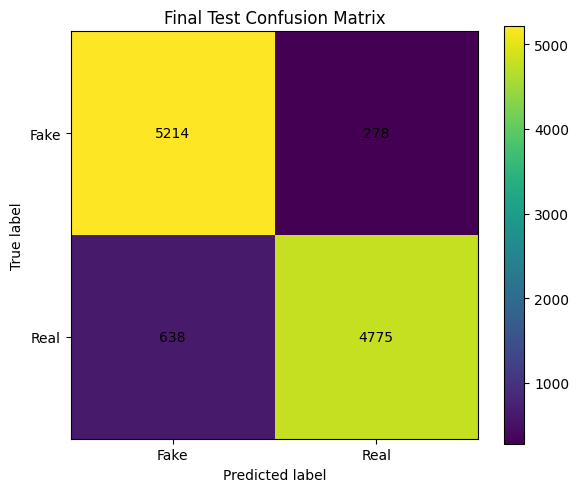

In [13]:
all_labels, all_predictions = [], []

model.eval()
with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        with autocast("cuda", dtype=torch.float16):
            logits = model(images).view(-1)
        predictions = (logits >= 0).long().cpu().numpy()

        all_labels.extend(labels.numpy().tolist())
        all_predictions.extend(predictions.tolist())

test_accuracy = accuracy_score(all_labels, all_predictions)
cm = confusion_matrix(all_labels, all_predictions, labels=[0, 1])
report = classification_report(
    all_labels, all_predictions,
    labels=[0, 1], target_names=["Fake", "Real"],
    output_dict=True, zero_division=0
)

print(f"Test accuracy: {test_accuracy:.4%}")
print(classification_report(
    all_labels, all_predictions,
    labels=[0, 1], target_names=["Fake", "Real"],
    digits=4, zero_division=0
))
print("Confusion matrix (rows=true, columns=predicted):")
print(cm)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm)
ax.set_xticks([0, 1], labels=["Fake", "Real"])
ax.set_yticks([0, 1], labels=["Fake", "Real"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Final Test Confusion Matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 9. Save metrics and verify output files

Evaluation metrics, plots, and checkpoint files are saved in the active Colab runtime. These files should be downloaded before the runtime is closed or reset, because `/content/` is temporary storage.


In [14]:
results = {
    "architecture": "InceptionResnetV1",
    "pretrained_weights": "VGGFace2",
    "task": "Binary deepfake image classification",
    "selected_checkpoint_epoch": int(best_checkpoint["epoch"]),
    "selection_metric": "validation loss",
    "test_accuracy": float(test_accuracy),
    "test_samples": int(len(all_labels)),
    "class_mapping": EXPECTED_MAPPING,
    "classification_report": report,
    "confusion_matrix": cm.tolist(),
}

results_json = os.path.join(RESULTS_DIR, "final_test_results.json")
with open(results_json, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

pd.DataFrame(
    cm,
    index=["Actual Fake", "Actual Real"],
    columns=["Predicted Fake", "Predicted Real"]
).to_csv(os.path.join(RESULTS_DIR, "confusion_matrix.csv"))

# Verify checkpoint and results files exist and are non-empty.
for path in (TRANSFER_BEST_PATH, FINETUNE_BEST_PATH, results_json):
    if not os.path.isfile(path) or os.path.getsize(path) == 0:
        raise IOError(f"Expected saved file missing or empty: {path}")
    print("VERIFIED:", path, f"({os.path.getsize(path)/(1024**2):.2f} MB)")

print(f"Final test accuracy for this run: {test_accuracy:.4%}")
print("Results saved under:", RESULTS_DIR)
print("Remember to download the checkpoint ZIP before ending the Colab session.")


VERIFIED: /content/drive/MyDrive/deepfake_fyp_project/checkpoints/best_inceptionresnet_vggface2_transfer.pth (89.97 MB)
VERIFIED: /content/drive/MyDrive/deepfake_fyp_project/checkpoints/best_inceptionresnet_vggface2_finetuned.pth (163.32 MB)
VERIFIED: /content/drive/MyDrive/deepfake_fyp_project/results/final_test_results.json (0.00 MB)
Final test accuracy for this run: 91.6002%
Results saved under: /content/drive/MyDrive/deepfake_fyp_project/results


## 10. Download checkpoint backups

After training, this cell packages the transfer-learning and fine-tuned checkpoints into a ZIP file and initiates a download to the local computer. The `.pth` files can later be uploaded to a new Colab runtime and placed in `/content/deepfake_fyp_project/checkpoints/` to reuse trained weights without repeating training.


In [ ]:
DOWNLOAD_CHECKPOINTS_TO_PC = True  # Set False if you do not want to download now.

if DOWNLOAD_CHECKPOINTS_TO_PC:
    from zipfile import ZipFile, ZIP_DEFLATED
    from google.colab import files

    checkpoint_bundle = "/content/deepfake_fyp_checkpoints.zip"
    checkpoint_paths = [TRANSFER_BEST_PATH, FINETUNE_BEST_PATH]
    for checkpoint_path in checkpoint_paths:
        if not os.path.isfile(checkpoint_path) or os.path.getsize(checkpoint_path) == 0:
            raise FileNotFoundError(
                f"Checkpoint missing or empty: {checkpoint_path}. "
                "Run the training cells first, or upload/place your existing checkpoints there."
            )

    with ZipFile(checkpoint_bundle, "w", compression=ZIP_DEFLATED) as archive:
        for checkpoint_path in checkpoint_paths:
            archive.write(checkpoint_path, arcname=os.path.basename(checkpoint_path))

    print(
        f"Checkpoint ZIP ready: {checkpoint_bundle} "
        f"({os.path.getsize(checkpoint_bundle)/(1024**2):.1f} MB)"
    )
    files.download(checkpoint_bundle)
else:
    print("PC download skipped. Set DOWNLOAD_CHECKPOINTS_TO_PC = True when you want a ZIP backup.")
